In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 16.9 MB/s eta 0:00:00


In [ ]:
# Grados de pertenencia (entre 0 y 1)
alto = 0.8
pesado = 0.4

print("OR  (unión):        ", max(alto, pesado))
print("AND (intersección): ", min(alto, pesado))
print("NOT (complemento):  ", round(1 - alto, 2))

OR  (unión):         0.8
AND (intersección):  0.4
NOT (complemento):   0.2


Propina sugerida: 19.85 %


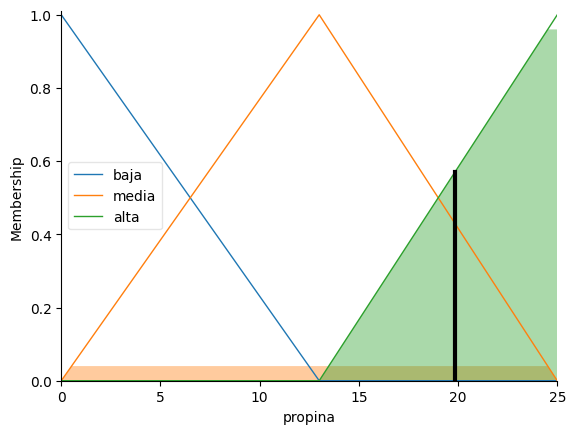

In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

comida   = ctrl.Antecedent(np.arange(0, 11, 1), 'comida')
servicio = ctrl.Antecedent(np.arange(0, 11, 1), 'servicio')
propina  = ctrl.Consequent(np.arange(0, 26, 1), 'propina')

comida.automf(names=['mala', 'regular', 'buena'])
servicio.automf(names=['mala', 'regular', 'buena'])

propina['baja']  = fuzz.trimf(propina.universe, [0, 0, 13])
propina['media'] = fuzz.trimf(propina.universe, [0, 13, 25])
propina['alta']  = fuzz.trimf(propina.universe, [13, 25, 25])

r1 = ctrl.Rule(servicio['mala'] | comida['mala'], propina['baja'])
r2 = ctrl.Rule(servicio['regular'], propina['media'])
r3 = ctrl.Rule(servicio['buena'] | comida['buena'], propina['alta'])

sistema = ctrl.ControlSystemSimulation(ctrl.ControlSystem([r1, r2, r3]))

sistema.input['comida'] = 6.5
sistema.input['servicio'] = 9.8
sistema.compute()

print("Propina sugerida:", round(sistema.output['propina'], 2), "%")

propina.view(sim=sistema)
plt.savefig("propina.png")
plt.show()